# Sklearn Compatibility Tests for tensorts

All problems start from ragged `(B, Ti, C)` input and exercise:
- `FunctionTransform` and `FeatureExtractor`
- `clone()`, `cross_val_score`, `cross_validate`, `GridSearchCV`
- Label propagation through `SlidingWindow`
- Nested `get_params` / `set_params` through deep pipelines

In [1]:
import sys
sys.path.insert(0, ".")

import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, cross_validate

from tensorts import (
    Dim, Flatten, Pipeline, RobustScaler, SklearnWrapper, SlidingWindow,
    StandardScaler, TimeTensor, make_statistical_extractor, Interpolate,
)
from tensorts.transforms.functional import FeatureExtractor, FunctionTransform, StatefulFunctionTransform
from tensorts.transforms.base import Scope, ChannelSelect
from tensorts.transforms.shape import PCA

## Data Generators

### make_har_data
HAR-style ragged dataset: 12 subjects x 3 classes x variable length 500-1500, 6 channels.

In [2]:
def make_har_data(n_subjects=12, n_classes=3, channels=6, seed=42):
    """
    HAR-style dataset: each subject has one variable-length recording per
    class (activity). Recording lengths vary by subject (500-1500 samples).
    Returns ragged TimeTensor with shape (B, Ti, 6).
    """
    rng = np.random.default_rng(seed)
    samples, labels = [], []
    for s in range(n_subjects):
        for c in range(n_classes):
            T = rng.integers(500, 1500)
            # Class-specific signal: sinusoid at different frequencies
            t = np.linspace(0, 1, T)
            base = np.sin(2 * np.pi * (c + 1) * 3 * t)
            signal = np.stack([base + 0.3 * rng.standard_normal(T)
                               for _ in range(channels)], axis=-1)
            samples.append(signal.astype(np.float32))
            labels.append(c)

    return TimeTensor.from_ragged(
        samples,
        channels=["acc_x", "acc_y", "acc_z", "gyro_x", "gyro_y", "gyro_z"],
        y=np.array(labels),
    )

### make_audio_data
Audio-like stereo clips: 24 clips, binary classification, variable length 1000-4000.

In [3]:
def make_audio_data(n_clips=24, channels=2, seed=7):
    """
    Audio-like dataset: variable-length stereo clips (1000-4000 samples).
    Binary classification (speech vs. noise).
    """
    rng = np.random.default_rng(seed)
    samples, labels = [], []
    for i in range(n_clips):
        T = rng.integers(1000, 4000)
        label = i % 2
        if label == 0:  # speech-like: harmonic
            t = np.linspace(0, 1, T)
            sig = np.column_stack([
                np.sin(2 * np.pi * 200 * t) + 0.1 * rng.standard_normal(T),
                np.sin(2 * np.pi * 400 * t) + 0.1 * rng.standard_normal(T),
            ])
        else:  # noise
            sig = rng.standard_normal((T, 2))
        samples.append(sig.astype(np.float32))
        labels.append(label)

    return TimeTensor.from_ragged(samples, channels=["left", "right"],
                                  y=np.array(labels))

### make_biosignal_data
ECG/biosignal: 20 recordings, 4 channels with different scales, NaN contamination in channel 3.

In [4]:
def make_biosignal_data(n_recordings=20, channels=4, seed=13):
    """
    ECG/biosignal-style: variable-length recordings (800-2500 samples),
    4 channels with very different scales (mV, bpm, RR-interval, SpO2).
    Binary classification.
    Includes mild NaN contamination in channel 3.
    """
    rng = np.random.default_rng(seed)
    samples, labels = [], []
    for i in range(n_recordings):
        T = rng.integers(800, 2500)
        label = i % 2
        t = np.linspace(0, 1, T)
        # ch0: ECG-like mV (~1.0 scale)
        # ch1: heart rate bpm (~70 scale)
        # ch2: RR interval ms (~800 scale)
        # ch3: SpO2 % (~98 scale) with some NaNs
        ch0 = np.sin(2 * np.pi * 1.2 * t * (1 + 0.2 * label)) + 0.05 * rng.standard_normal(T)
        ch1 = 70 + 5 * label + rng.standard_normal(T)
        ch2 = 800 - 30 * label + 10 * rng.standard_normal(T)
        ch3 = 98 + rng.standard_normal(T) * 0.5
        # inject ~2% NaNs in ch3
        nan_idx = rng.choice(T, size=T // 50, replace=False)
        ch3[nan_idx] = np.nan
        sig = np.column_stack([ch0, ch1, ch2, ch3]).astype(np.float64)
        samples.append(sig)
        labels.append(label)

    return TimeTensor.from_ragged(
        samples,
        channels=["ecg", "hr", "rr", "spo2"],
        y=np.array(labels),
    )

### make_financial_data
Financial time series: 6 assets x 20 periods, 3 channels (log-price, volume, volatility), regression target.

In [5]:
def make_financial_data(n_assets=6, n_periods=20, channels=3, seed=99):
    """
    Financial-style: n_periods variable-length price series per asset group.
    3 channels: log-price, volume, volatility (very different scales).
    Regression target: next-period return.
    """
    rng = np.random.default_rng(seed)
    samples, labels = [], []
    for a in range(n_assets):
        for p in range(n_periods):
            T = rng.integers(300, 1000)
            # log-price: random walk
            log_price = np.cumsum(rng.standard_normal(T) * 0.01)
            # volume: log-normal, much larger scale
            volume = np.exp(rng.standard_normal(T) + 8)
            # volatility: GARCH-like, small values
            vol = np.abs(rng.standard_normal(T)) * 0.02
            sig = np.column_stack([log_price, volume, vol]).astype(np.float64)
            samples.append(sig)
            # Regression target: total return over period
            labels.append(float(log_price[-1] - log_price[0]))

    return TimeTensor.from_ragged(samples, channels=["log_price", "volume", "vol"],
                                  y=np.array(labels))

---
## Problem 1: HAR Classification

**Pipeline:** Ragged `(B, Ti, 6)` -> `FunctionTransform` (pre-emphasis) -> `StandardScaler` -> `SlidingWindow` -> `StatisticalFeatures` -> `Flatten` -> `PCA`

**Tricky parts:**
- `clone()` must survive `FunctionTransform` (fn is a function reference)
- `SlidingWindow` multiplies B by K, labels must propagate correctly
- `StratifiedKFold` works on the expanded label vector from `Xt.y`
- `get_params` / `set_params` must work through the full depth

### Step 1: Create data and inspect

In [7]:
X = make_har_data()
y = X.y
print(f"Input: {X}")
print(f"Samples: {X.n_samples}, Classes: {np.unique(y)}")
print(f"Lengths: min={min(X.lengths)}, max={max(X.lengths)}, is_ragged={X.is_ragged}")

Input: TimeTensor(ragged, shape=(36, [variable], 6), dims=(BATCH, TIME, CHANNEL), y=(36,))
Samples: 36, Classes: [0 1 2]
Lengths: min=550, max=1494, is_ragged=True


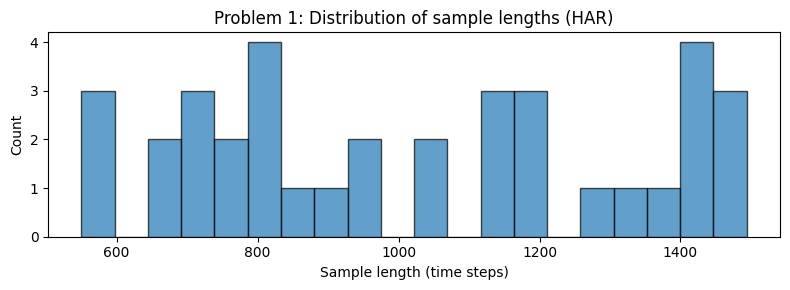

In [8]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(X.lengths, bins=20, edgecolor="black", alpha=0.7)
ax.set_xlabel("Sample length (time steps)")
ax.set_ylabel("Count")
ax.set_title("Problem 1: Distribution of sample lengths (HAR)")
plt.tight_layout()
plt.show()

### Step 2: Pre-emphasis (FunctionTransform, PER_CHANNEL)

In [9]:
def pre_emphasis(signal_1d, coeff=0.97):
    out = np.empty_like(signal_1d)
    out[0] = signal_1d[0]
    out[1:] = signal_1d[1:] - coeff * signal_1d[:-1]
    return out

pre_emph = FunctionTransform(pre_emphasis, scope=Scope.PER_CHANNEL, fn_kwargs={"coeff": 0.97}, name="pre_emphasis")
X1 = pre_emph.fit_transform(X)
print(f"After pre-emphasis: is_ragged={X1.is_ragged}, n_samples={X1.n_samples}")

After pre-emphasis: is_ragged=True, n_samples=36


In [18]:
X.shape, X[0].shape

((36, -1, 6), (1, -1, 6))

In [15]:
X[0].samples[0].shape

(589, 6)

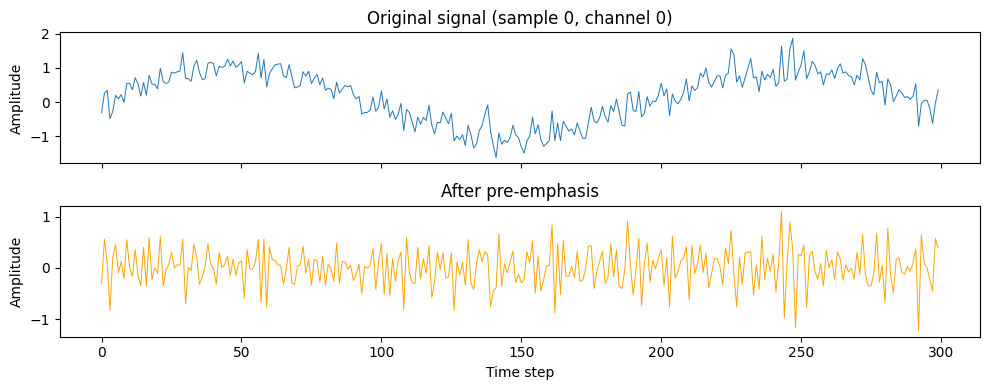

In [22]:
# Plot: original vs pre-emphasized for first sample, channel 0
sample_orig = X[0].samples[0][:, 0] # if X[0].samples[0].ndim == 2 else X[0].data
sample_pre = X1[0].samples[0][:, 0] # if X1[0].samples[0].ndim == 2 else X1[0].data

fig, axes = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
axes[0].plot(sample_orig[:300], linewidth=0.7)
axes[0].set_title("Original signal (sample 0, channel 0)")
axes[0].set_ylabel("Amplitude")
axes[1].plot(sample_pre[:300], linewidth=0.7, color="orange")
axes[1].set_title("After pre-emphasis")
axes[1].set_ylabel("Amplitude")
axes[1].set_xlabel("Time step")
plt.tight_layout()
plt.show()

### Step 3: StandardScaler on ragged

In [23]:
scaler = StandardScaler()
X2 = scaler.fit_transform(X1)
print(f"After scaler: is_ragged={X2.is_ragged}")
print(f"Learned mean shape: {scaler.mean_.shape}")
print(f"Learned std shape: {scaler.std_.shape}")

After scaler: is_ragged=True
Learned mean shape: (1, 6)
Learned std shape: (1, 6)


### Step 4: SlidingWindow (ragged -> dense)

In [24]:
window = SlidingWindow(size=100, stride=50, label_strategy="repeat", flatten_batch=True)
X3 = window.fit_transform(X2)
print(f"After window: shape={X3.shape}, is_ragged={X3.is_ragged}")
print(f"Labels expanded: {len(y)} -> {len(X3.y)}")
print(f"Window counts: {X3.metadata.get('_window_counts', 'N/A')}")

After window: shape=(683, 100, 6), is_ragged=False
Labels expanded: 36 -> 683
Window counts: [10, 24, 22, 19, 13, 21, 28, 15, 12, 10, 10, 26, 26, 13, 13, 22, 27, 27, 17, 15, 12, 22, 27, 18, 20, 28, 21, 15, 15, 16, 27, 16, 21, 13, 28, 14]


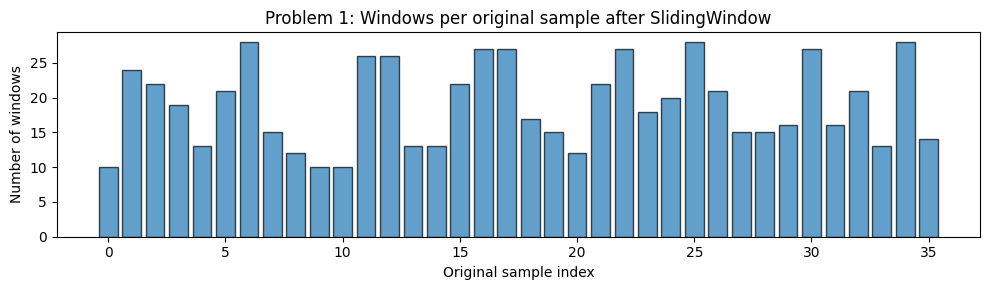

In [25]:
# Plot: bar chart showing number of windows per original sample
window_counts = X3.metadata.get('_window_counts', None)
if window_counts is not None:
    fig, ax = plt.subplots(figsize=(10, 3))
    ax.bar(range(len(window_counts)), window_counts, alpha=0.7, edgecolor="black")
    ax.set_xlabel("Original sample index")
    ax.set_ylabel("Number of windows")
    ax.set_title("Problem 1: Windows per original sample after SlidingWindow")
    plt.tight_layout()
    plt.show()
else:
    print("Window counts not available in metadata")

### Step 5: Statistical features

In [26]:
stats = make_statistical_extractor(["mean", "std", "min", "max", "energy"])
X4 = stats.fit_transform(X3)
print(f"After stats: shape={X4.shape}, dims={X4.dims}")
print(f"Feature names: {stats.feature_names_out_}")

After stats: shape=(683, 5, 6), dims=(Dim.BATCH, Dim.FEATURE, Dim.CHANNEL)
Feature names: ['mean', 'std', 'min', 'max', 'energy']


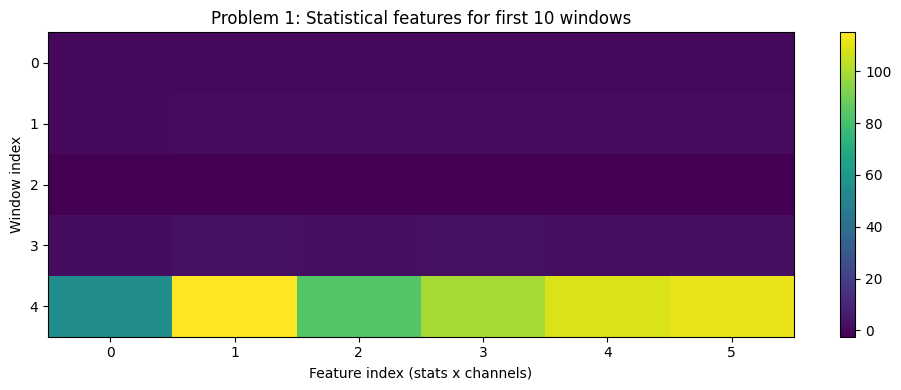

In [28]:
# Plot: heatmap of feature values for first 10 windows (features x channels)
n_show = min(10, X4.n_samples)
feat_data = X4.data[:n_show]

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(feat_data[0], aspect="auto", cmap="viridis")
ax.set_xlabel("Feature index (stats x channels)")
ax.set_ylabel("Window index")
ax.set_title("Problem 1: Statistical features for first 10 windows")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

### Step 6: Flatten

In [29]:
flat = Flatten()
X5 = flat.fit_transform(X4)
print(f"After flatten: shape={X5.shape}")

After flatten: shape=(683, 30)


### Step 7: PCA

In [31]:
pca = PCA(n_components=0.95)
X6 = pca.fit_transform(X5)
print(f"After PCA: shape={X6.shape}")
print(f"Explained variance ratio: {pca.explained_variance_[:10].round(3)}")

After PCA: shape=(683, 6)
Explained variance ratio: [355.948 307.611 295.062 278.533 265.493 239.162]


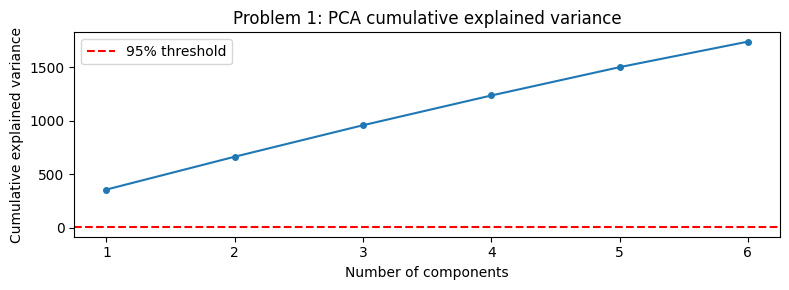

In [33]:
# Plot: cumulative explained variance
cumvar = np.cumsum(pca.explained_variance_)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(range(1, len(cumvar) + 1), cumvar, marker="o", markersize=4)
ax.axhline(0.95, color="red", linestyle="--", label="95% threshold")
ax.set_xlabel("Number of components")
ax.set_ylabel("Cumulative explained variance")
ax.set_title("Problem 1: PCA cumulative explained variance")
ax.legend()
plt.tight_layout()
plt.show()

### Clone and get_params test

In [34]:
pipe = Pipeline([
    ("pre_emph", FunctionTransform(pre_emphasis, scope=Scope.PER_CHANNEL,
                                    fn_kwargs={"coeff": 0.97}, name="pre_emphasis")),
    ("scaler",   StandardScaler()),
    ("window",   SlidingWindow(size=100, stride=50, label_strategy="repeat", flatten_batch=True)),
    ("stats",    make_statistical_extractor(["mean", "std", "min", "max", "energy"])),
    ("flatten",  Flatten()),
    ("pca",      PCA(n_components=0.95)),
])

cloned = clone(pipe)
print(f"Clone ok: {type(cloned['pre_emph'].fn)}")
params = pipe.get_params(deep=True)
print(f"Nested params: {[k for k in params if '__' in k]}")

Clone ok: <class 'function'>
Nested params: ['pre_emph__fn', 'pre_emph__scope', 'pre_emph__fn_args', 'pre_emph__fn_kwargs', 'pre_emph__name', 'scaler__eps', 'window__size', 'window__stride', 'window__label_strategy', 'window__flatten_batch', 'window__drop_last', 'stats__fn', 'stats__input_dim', 'stats__output_dims', 'stats__fn_args', 'stats__fn_kwargs', 'stats__name', 'stats__functions', 'stats__scope', 'pca__n_components', 'pca__whiten']


### cross_val_score

In [35]:
wrapper = SklearnWrapper(pipe, LogisticRegression(max_iter=300))
try:
    scores = cross_val_score(wrapper, X, y, cv=StratifiedKFold(3, shuffle=True, random_state=0))
    print(f"Scores: {scores.round(3)}, Mean: {scores.mean():.3f}")
except Exception as e:
    print(f"[EXPECTED FAILURE] cross_val_score failed: {type(e).__name__}: {e}")
    print("  -> ROOT CAUSE: score(X_test, y_test) uses sklearn-sliced y_test (length=B_test)")
    print("     but Xt_test has B_test * K windows. score() must use Xt.y instead.")

Scores: [0.349 0.358 0.376], Mean: 0.361


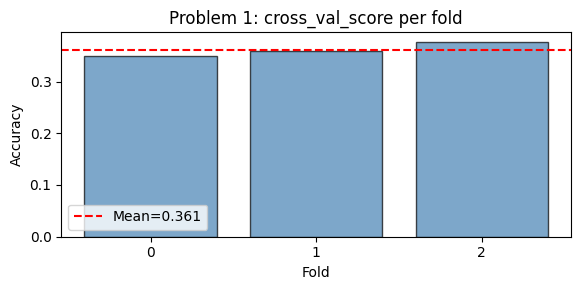

In [36]:
# Plot: bar chart of fold scores (if available)
try:
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.bar(range(len(scores)), scores, alpha=0.7, edgecolor="black", color="steelblue")
    ax.axhline(scores.mean(), color="red", linestyle="--", label=f"Mean={scores.mean():.3f}")
    ax.set_xlabel("Fold")
    ax.set_ylabel("Accuracy")
    ax.set_title("Problem 1: cross_val_score per fold")
    ax.set_xticks(range(len(scores)))
    ax.legend()
    plt.tight_layout()
    plt.show()
except NameError:
    print("Scores not available (cross_val_score failed).")

---
## Problem 2: Audio -- FeatureExtractor + GridSearchCV

**Pipeline:** Ragged `(B, Ti, 2)` -> `StandardScaler` -> `FeatureExtractor` (FFT energy bands) -> `Flatten` -> `PCA`

**Tricky parts:**
- `FeatureExtractor` changes `(B, T, C)` -> `(B, n_bands, C)`, then `Flatten` -> `(B, n_bands*C)`
- `clone()` must deepcopy the fn inside `FeatureExtractor`
- `GridSearchCV` calls `clone` + `set_params` on the full wrapper
- `FeatureExtractor.output_dims` must be in `get_params`

### Step 1: Create audio data and inspect

In [37]:
X = make_audio_data()
y = X.y
print(f"Input: {X}")
print(f"Samples: {X.n_samples}, Classes: {np.unique(y)}")
print(f"Lengths: min={min(X.lengths)}, max={max(X.lengths)}, is_ragged={X.is_ragged}")

Input: TimeTensor(ragged, shape=(24, [variable], 2), dims=(BATCH, TIME, CHANNEL), y=(24,))
Samples: 24, Classes: [0 1]
Lengths: min=1174, max=3888, is_ragged=True


In [38]:
# Plot: first 2 clips (speech-like vs noise-like) - time domain
fig, axes = plt.subplots(2, 1, figsize=(10, 4))
for idx, label_name in [(0, "Speech-like (class 0)"), (1, "Noise (class 1)")]:
    sample = X.samples[idx]
    if sample.ndim == 2:
        axes[idx].plot(sample[:500, 0], linewidth=0.5, label="left")
        axes[idx].plot(sample[:500, 1], linewidth=0.5, alpha=0.6, label="right")
    else:
        axes[idx].plot(sample[:500], linewidth=0.5)
    axes[idx].set_title(label_name)
    axes[idx].set_ylabel("Amplitude")
    axes[idx].legend(loc="upper right", fontsize=8)
axes[1].set_xlabel("Time step")
plt.tight_layout()
plt.show()

### Step 2: StandardScaler on ragged

In [ ]:
scaler = StandardScaler()
X2 = scaler.fit_transform(X)
print(f"After scaler: is_ragged={X2.is_ragged}")
print(f"Learned mean: {scaler.mean_}")
print(f"Learned std: {scaler.std_}")

### Step 3: FeatureExtractor (FFT energy bands)

In [ ]:
def fft_energy_bands(signal_1d, n_bands=8):
    spec = np.abs(np.fft.rfft(signal_1d)) ** 2
    band_size = max(1, len(spec) // n_bands)
    bands = np.array([spec[i*band_size:(i+1)*band_size].mean() for i in range(n_bands)])
    return np.log1p(bands)

fe = FeatureExtractor(fn=fft_energy_bands, input_dim=Dim.TIME, output_dims=(Dim.FREQUENCY,),
                       fn_kwargs={"n_bands": 8}, name="fft_energy_bands")
X3 = fe.fit_transform(X2)
print(f"After FFT bands: {X3.shape}, dims={X3.dims}")

In [ ]:
# Plot: bar chart of 8 frequency bands for speech vs noise sample
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax_idx, (sample_idx, label_name) in enumerate([(0, "Speech (class 0)"), (1, "Noise (class 1)")]):
    sample = X3[sample_idx].data
    if sample.ndim == 2:
        n_bands = sample.shape[0]
        x_pos = np.arange(n_bands)
        width = 0.35
        axes[ax_idx].bar(x_pos - width/2, sample[:, 0], width, label="left", alpha=0.7)
        axes[ax_idx].bar(x_pos + width/2, sample[:, 1], width, label="right", alpha=0.7)
    else:
        axes[ax_idx].bar(range(len(sample)), sample, alpha=0.7)
    axes[ax_idx].set_title(label_name)
    axes[ax_idx].set_xlabel("Frequency band")
    axes[ax_idx].legend(fontsize=8)
axes[0].set_ylabel("Log energy")
plt.suptitle("Problem 2: FFT energy bands", fontsize=12)
plt.tight_layout()
plt.show()

### Step 4: Flatten

In [ ]:
flat = Flatten()
X4 = flat.fit_transform(X3)
print(f"After flatten: shape={X4.shape}")

### Step 5: PCA

In [ ]:
pca = PCA(n_components=10)
X5 = pca.fit_transform(X4)
print(f"After PCA: shape={X5.shape}")
print(f"Explained variance ratio: {pca.explained_variance_ratio_.round(3)}")

In [ ]:
# Plot: PCA projection (scatter plot, colored by class)
fig, ax = plt.subplots(figsize=(6, 5))
pca_data = X5.data
for cls in np.unique(y):
    mask = y == cls
    label = "Speech" if cls == 0 else "Noise"
    ax.scatter(pca_data[mask, 0], pca_data[mask, 1], alpha=0.7, label=label, s=40)
ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")
ax.set_title("Problem 2: PCA projection colored by class")
ax.legend()
plt.tight_layout()
plt.show()

### Clone test

In [ ]:
pipe = Pipeline([
    ("scaler",   StandardScaler()),
    ("fft_feat", FeatureExtractor(
        fn=fft_energy_bands,
        input_dim=Dim.TIME,
        output_dims=(Dim.FREQUENCY,),
        fn_kwargs={"n_bands": 8},
        name="fft_energy_bands",
    )),
    ("flatten",  Flatten()),
    ("pca",      PCA(n_components=10)),
])

cloned = clone(pipe)
print(f"Clone ok: fn={cloned['fft_feat'].fn.__name__}, output_dims={cloned['fft_feat'].output_dims}")

params = pipe.get_params(deep=True)
fft_params = {k: v for k, v in params.items() if 'fft_feat' in k}
print(f"FeatureExtractor params: {fft_params}")

### GridSearchCV

In [ ]:
wrapper = SklearnWrapper(pipe, LogisticRegression(max_iter=500))
param_grid = {"pipeline__pca__n_components": [4, 8], "estimator__C": [0.1, 1.0]}
gs = GridSearchCV(wrapper, param_grid, cv=3, refit=True, n_jobs=1)
try:
    gs.fit(X, y)
    print(f"Best params: {gs.best_params_}")
    print(f"Best score: {gs.best_score_:.3f}")
except Exception as e:
    print(f"[FAILURE] GridSearchCV: {type(e).__name__}: {e}")

In [ ]:
# Plot: heatmap of GridSearchCV mean scores across parameter combinations
try:
    results = gs.cv_results_
    n_components_vals = param_grid["pipeline__pca__n_components"]
    c_vals = param_grid["estimator__C"]
    mean_scores = results["mean_test_score"].reshape(len(n_components_vals), len(c_vals))

    fig, ax = plt.subplots(figsize=(6, 4))
    im = ax.imshow(mean_scores, cmap="YlOrRd", aspect="auto")
    ax.set_xticks(range(len(c_vals)))
    ax.set_xticklabels([f"C={c}" for c in c_vals])
    ax.set_yticks(range(len(n_components_vals)))
    ax.set_yticklabels([f"n_comp={n}" for n in n_components_vals])
    ax.set_title("Problem 2: GridSearchCV mean scores")
    for i in range(len(n_components_vals)):
        for j in range(len(c_vals)):
            ax.text(j, i, f"{mean_scores[i, j]:.3f}", ha="center", va="center", fontsize=12)
    plt.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f"Cannot plot GridSearchCV results: {e}")

---
## Problem 3: Biosignal -- StatefulFunctionTransform

**Pipeline:** Ragged `(B, Ti, 4)` with NaNs -> `Interpolate` -> `RobustScaler` -> `StatefulFunctionTransform` (peak norm) -> `FunctionTransform` (first diff) -> `FeatureExtractor` (total energy) -> `Flatten`

**Tricky parts:**
- `StatefulFunctionTransform` clone must preserve `fit_fn` and `transform_fn`
- `FunctionTransform` changes T to T-1: ragged stays ragged
- `FeatureExtractor` with scalar `output_dims=()` collapses TIME
- After scalar extraction ragged -> dense: each sample becomes `(C,)`

### Step 1: Create data, show NaN contamination

In [ ]:
X = make_biosignal_data()
y = X.y
print(f"Input: {X}")
print(f"Samples: {X.n_samples}, Classes: {np.unique(y)}")
print(f"Lengths: min={min(X.lengths)}, max={max(X.lengths)}, is_ragged={X.is_ragged}")

# Count NaNs in first sample
sample0 = X.samples[0]
for ch in range(sample0.shape[1]):
    nan_count = np.isnan(sample0[:, ch]).sum()
    print(f"  Channel {ch} ({X.channels[ch]}): {nan_count} NaNs")

In [ ]:
# Plot: one sample showing NaN gaps in channel 3 (spo2)
sample0 = X.samples[0]
fig, ax = plt.subplots(figsize=(10, 3))
ch3 = sample0[:, 3].copy()
nan_mask = np.isnan(ch3)
ax.plot(ch3, linewidth=0.7, label="SpO2 (with NaNs)")
ax.scatter(np.where(nan_mask)[0], np.full(nan_mask.sum(), np.nanmean(ch3)),
           color="red", s=10, zorder=5, label=f"NaN locations ({nan_mask.sum()} pts)")
ax.set_xlabel("Time step")
ax.set_ylabel("SpO2 (%)")
ax.set_title("Problem 3: NaN contamination in SpO2 channel (sample 0)")
ax.legend()
plt.tight_layout()
plt.show()

### Step 2: Interpolate

In [ ]:
interp = Interpolate(method="linear")
X1 = interp.fit_transform(X)

# Verify NaNs are gone
sample0_after = X1[0].data
for ch in range(sample0_after.shape[1]):
    nan_count = np.isnan(sample0_after[:, ch]).sum()
    print(f"  Channel {ch} ({X.channels[ch]}): {nan_count} NaNs after interpolation")

In [ ]:
# Plot: before/after NaN filling for one sample, channel 3
fig, axes = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
before = X.samples[0][:, 3]
after = X1.samples[0][:, 3]
axes[0].plot(before, linewidth=0.7)
axes[0].set_title("Before interpolation (SpO2, sample 0)")
axes[0].set_ylabel("SpO2")
axes[1].plot(after, linewidth=0.7, color="green")
axes[1].set_title("After interpolation")
axes[1].set_ylabel("SpO2")
axes[1].set_xlabel("Time step")
plt.tight_layout()
plt.show()

### Step 3: RobustScaler

In [ ]:
rscaler = RobustScaler()
X2 = rscaler.fit_transform(X1)

# Print: channel scales before/after
print("Channel statistics before scaling:")
for ch in range(X1[0].data.shape[1]):
    all_vals = np.concatenate([X1[i].data[:, ch] for i in range(X1.n_samples)])
    print(f"  {X.channels[ch]}: mean={all_vals.mean():.2f}, std={all_vals.std():.2f}")

print("\nChannel statistics after scaling:")
for ch in range(X2[0].data.shape[1]):
    all_vals = np.concatenate([X2[i].data[:, ch] for i in range(X2.n_samples)])
    print(f"  {X.channels[ch]}: mean={all_vals.mean():.2f}, std={all_vals.std():.2f}")

### Step 4: StatefulFunctionTransform (peak normalization)

In [ ]:
def fit_peak(channel_1d):
    return float(np.nanmax(np.abs(channel_1d))) + 1e-8

def transform_peak(channel_1d, peak):
    return channel_1d / peak

peak_norm = StatefulFunctionTransform(
    fit_fn=fit_peak, transform_fn=transform_peak,
    scope=Scope.PER_CHANNEL, name="peak_norm",
)
X3 = peak_norm.fit_transform(X2)

# Print: learned peak values per channel
print("Learned peak values per channel:")
if hasattr(peak_norm, 'state_') and peak_norm.state_ is not None:
    print(f"  State: {peak_norm.state_}")
elif hasattr(peak_norm, 'states_') and peak_norm.states_ is not None:
    for ch_idx, state in enumerate(peak_norm.states_):
        print(f"  {X.channels[ch_idx]}: peak={state}")
else:
    print("  (inspect peak_norm attributes to find stored state)")
    print(f"  Attributes: {[a for a in dir(peak_norm) if not a.startswith('_')]}")

### Step 5: FunctionTransform (first difference)

In [ ]:
def first_diff(signal_1d):
    return np.diff(signal_1d)

diff_transform = FunctionTransform(first_diff, scope=Scope.PER_CHANNEL, name="first_diff")
X4 = diff_transform.fit_transform(X3)

# Print: shape change (T -> T-1), still ragged
print(f"Before diff: sample 0 length={X3[0].data.shape[0]}")
print(f"After diff:  sample 0 length={X4[0].data.shape[0]}")
print(f"Still ragged: {X4.is_ragged}")

### Step 6: FeatureExtractor (scalar: total energy)

In [ ]:
def total_energy(signal_1d):
    return np.array(np.sum(signal_1d ** 2))

energy_fe = FeatureExtractor(
    fn=total_energy,
    input_dim=Dim.TIME,
    output_dims=(),  # scalar per channel -> collapses TIME entirely
    name="total_energy",
)
X5 = energy_fe.fit_transform(X4)

# Print: ragged -> dense, shape
print(f"After energy extraction: shape={X5.shape}, is_ragged={X5.is_ragged}")
print(f"Dims: {X5.dims}")

### Step 7: Flatten

In [ ]:
flat = Flatten()
X6 = flat.fit_transform(X5)
print(f"After flatten: shape={X6.shape}")
print(f"n_samples preserved: {X6.n_samples} == {X.n_samples}")

### Clone test

In [ ]:
pipe = Pipeline([
    ("interp",  Interpolate(method="linear")),
    ("scaler",  RobustScaler()),
    ("peak",    StatefulFunctionTransform(
        fit_fn=fit_peak, transform_fn=transform_peak,
        scope=Scope.PER_CHANNEL, name="peak_norm",
    )),
    ("diff",    FunctionTransform(first_diff, scope=Scope.PER_CHANNEL, name="first_diff")),
    ("energy",  FeatureExtractor(
        fn=total_energy,
        input_dim=Dim.TIME,
        output_dims=(),
        name="total_energy",
    )),
    ("flatten", Flatten()),
])

cloned = clone(pipe)
print(f"clone() ok:")
print(f"  fit_fn survived: {callable(cloned['peak'].fit_fn)}")
print(f"  transform_fn survived: {callable(cloned['peak'].transform_fn)}")
print(f"  FunctionTransform fn survived: {callable(cloned['diff'].fn)}")
print(f"  FeatureExtractor output_dims survived: {cloned['energy'].output_dims}")

params = pipe.get_params(deep=True)
peak_params = {k: v for k, v in params.items() if 'peak' in k}
print(f"\nStatefulFunctionTransform params: {list(peak_params.keys())}")

### cross_validate with train scores

In [ ]:
wrapper = SklearnWrapper(pipe, LogisticRegression(max_iter=500))
try:
    cv_results = cross_validate(wrapper, X, y,
                                cv=StratifiedKFold(3, shuffle=True, random_state=0),
                                return_train_score=True)
    print(f"Test scores:  {cv_results['test_score'].round(3)}")
    print(f"Train scores: {cv_results['train_score'].round(3)}")
    print(f"Mean test:  {cv_results['test_score'].mean():.3f}")
    print(f"Mean train: {cv_results['train_score'].mean():.3f}")
except Exception as e:
    print(f"[FAILURE] cross_validate: {type(e).__name__}: {e}")

---
## Problem 4: Financial Regression -- GridSearchCV

**Pipeline:** Ragged `(B, Ti, 3)` -> `ChannelSelect` + `log1p` on volume -> `RobustScaler` -> `SlidingWindow` -> `FeatureExtractor` (autocorrelation) -> `Flatten`

**Tricky parts:**
- `GridSearchCV` must clone and `set_params` on `SlidingWindow.size` (int) -- nested deep
- `FeatureExtractor.fn_kwargs` must survive clone
- Regression: target is continuous, use `Ridge` + `scoring='r2'`
- `SlidingWindow` for regression with `label_strategy='repeat'`: y expands too
- `score(X_test, y_test)` label-length mismatch (same issue as Problem 1)

### Step 1: Create data, inspect

In [ ]:
X = make_financial_data()
y = X.y
print(f"Input: {X}")
print(f"y dtype={y.dtype}, y[:5]={y[:5].round(4)}")
print(f"Lengths: min={min(X.lengths)}, max={max(X.lengths)}, is_ragged={X.is_ragged}")

In [ ]:
# Plot: one asset's log-price, volume, volatility (3 subplots)
sample = X.samples[0]
fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
channel_names = ["Log-price", "Volume", "Volatility"]
colors = ["steelblue", "orange", "green"]
for ch in range(3):
    axes[ch].plot(sample[:, ch], linewidth=0.7, color=colors[ch])
    axes[ch].set_ylabel(channel_names[ch])
    axes[ch].set_title(f"Channel: {channel_names[ch]}")
axes[2].set_xlabel("Time step")
plt.suptitle("Problem 4: Financial data (sample 0)", fontsize=12)
plt.tight_layout()
plt.show()

### Step 2: ChannelSelect + log1p on volume only

In [ ]:
def log1p_fn(x):
    return np.log1p(np.abs(x)) * np.sign(x)

log_vol = ChannelSelect(
    channels="volume",
    transform=FunctionTransform(log1p_fn, scope=Scope.PER_CHANNEL, name="log1p"),
)
X1 = log_vol.fit_transform(X)

# Print: verify other channels unchanged
print("Verify channel-selective transform:")
print(f"  Log-price (ch0) unchanged: {np.allclose(X.samples[0][:5, 0], X1.samples[0][:5, 0])}")
print(f"  Volume (ch1) transformed:  orig={X.samples[0][:3, 1].round(1)} -> {X1.samples[0][:3, 1].round(4)}")
print(f"  Volatility (ch2) unchanged: {np.allclose(X.samples[0][:5, 2], X1.samples[0][:5, 2])}")

### Step 3: RobustScaler

In [ ]:
rscaler = RobustScaler()
X2 = rscaler.fit_transform(X1)
print(f"After RobustScaler: is_ragged={X2.is_ragged}")

### Step 4: SlidingWindow

In [ ]:
window = SlidingWindow(size=50, stride=25, label_strategy="repeat", flatten_batch=True)
X3 = window.fit_transform(X2)
print(f"After window: shape={X3.shape}, is_ragged={X3.is_ragged}")
print(f"Labels expanded: {len(y)} -> {len(X3.y)}")
print(f"y (regression target) sample: {X3.y[:5].round(4)}")

### Step 5: FeatureExtractor (autocorrelation lag-1)

In [ ]:
def autocorr_lag1(signal_1d):
    if len(signal_1d) < 2:
        return np.array(0.0)
    x = signal_1d - signal_1d.mean()
    denom = np.dot(x, x)
    if denom < 1e-10:
        return np.array(0.0)
    return np.array(np.dot(x[:-1], x[1:]) / denom)

autocorr_fe = FeatureExtractor(
    fn=autocorr_lag1,
    input_dim=Dim.TIME,
    output_dims=(),  # scalar per channel: (B*K, W, C) -> (B*K, C)
    name="autocorr_lag1",
)
X4 = autocorr_fe.fit_transform(X3)

# Print: shape after, verify TIME collapsed
print(f"After autocorrelation: shape={X4.shape}, dims={X4.dims}")
print(f"TIME axis collapsed: {Dim.TIME not in X4.dims}")

### Step 6: Flatten

In [ ]:
flat = Flatten()
X5 = flat.fit_transform(X4)
print(f"After flatten: shape={X5.shape}")

### Clone test

In [ ]:
pipe = Pipeline([
    ("log_vol",  ChannelSelect(
        channels="volume",
        transform=FunctionTransform(log1p_fn, scope=Scope.PER_CHANNEL, name="log1p"),
    )),
    ("scaler",   RobustScaler()),
    ("window",   SlidingWindow(size=50, stride=25, label_strategy="repeat", flatten_batch=True)),
    ("autocorr", FeatureExtractor(
        fn=autocorr_lag1,
        input_dim=Dim.TIME,
        output_dims=(),
        name="autocorr_lag1",
    )),
    ("flatten",  Flatten()),
])

cloned = clone(pipe)
print(f"Clone ok:")
print(f"  SlidingWindow size={cloned['window'].size}, stride={cloned['window'].stride}")
print(f"  ChannelSelect inner fn: {callable(cloned['log_vol'].inner.fn)}")
print(f"  FeatureExtractor fn: {cloned['autocorr'].fn.__name__}")

### Nested get_params / set_params test

In [ ]:
params = pipe.get_params(deep=True)
window_params = {k: v for k, v in params.items() if 'window' in k and '__' in k}
print(f"SlidingWindow params in Pipeline: {window_params}")

# set_params roundtrip
pipe.set_params(**{"window__size": 60, "window__stride": 30})
print(f"After set_params: size={pipe['window'].size}, stride={pipe['window'].stride}")
pipe.set_params(**{"window__size": 50, "window__stride": 25})  # restore
print(f"Restored: size={pipe['window'].size}, stride={pipe['window'].stride}")

### GridSearchCV

In [ ]:
wrapper = SklearnWrapper(pipe, Ridge())
param_grid = {
    "pipeline__window__size": [30, 50],
    "pipeline__window__stride": [15, 25],
    "estimator__alpha": [0.1, 1.0],
}
gs = GridSearchCV(wrapper, param_grid, cv=3, scoring="r2", n_jobs=1)
try:
    gs.fit(X, y)
    print(f"Best params: {gs.best_params_}")
    print(f"Best R2: {gs.best_score_:.3f}")
except Exception as e:
    print(f"[EXPECTED or FAILURE] GridSearchCV: {type(e).__name__}: {e}")
    if "operands could not be broadcast" in str(e) or "y" in str(e).lower():
        print("  -> ROOT CAUSE: Same label-length mismatch as Problem 1.")
        print("     score(X_test, y_test) -- y_test has original length,")
        print("     but Xt_test has K*B_test windows after SlidingWindow.")
        print("  -> NEXT STEP: SklearnWrapper.score() must use Xt.y when available.")

In [ ]:
# Plot: best R2 across parameter grid
try:
    results = gs.cv_results_
    mean_scores = results["mean_test_score"]
    params_list = results["params"]
    
    fig, ax = plt.subplots(figsize=(10, 4))
    labels = [f"w={p['pipeline__window__size']},s={p['pipeline__window__stride']},a={p['estimator__alpha']}"
              for p in params_list]
    colors = ["steelblue" if s == max(mean_scores) else "lightsteelblue" for s in mean_scores]
    ax.barh(range(len(mean_scores)), mean_scores, color=colors, edgecolor="black")
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel("Mean R2 score")
    ax.set_title("Problem 4: GridSearchCV R2 scores across parameter combinations")
    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f"Cannot plot GridSearchCV results: {e}")